In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime


In [2]:
data_emas = pd.read_excel('Data_Emas.xlsx', sheet_name="Sheet1")
data_inflasi = pd.read_excel('Data_Inflasi.xlsx', sheet_name="Data Inflasi")
data_kurs = pd.read_excel('Data_Kurs.xlsx', sheet_name="Informasi Kurs Jisdor")
data_bunga = pd.read_excel('Data_Bunga.xlsx', sheet_name="BI-7Day-RR")

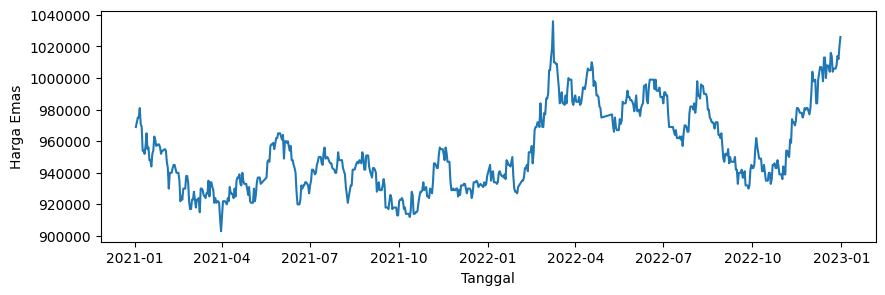

,tanggal,harga
0,2021-01-02,969000
1,2021-01-04,975000
2,2021-01-05,975000
3,2021-01-06,981000
4,2021-01-07,971000


In [14]:
x = np.array(data_emas['tanggal'])
y = np.array(data_emas['harga'])
plt.figure(figsize=(10,3))
#plt.title("Data Harga Emas Selama 1 Tahun")
plt.xlabel("Tanggal")
plt.ylabel("Harga Emas")
#plt.grid()
#labels, locations = plt.yticks()
#plt.yticks(labels, (labels/1).astype(int))
plt.ticklabel_format(style='plain')
plt.plot(x, y)
plt.show()
data_emas.head()

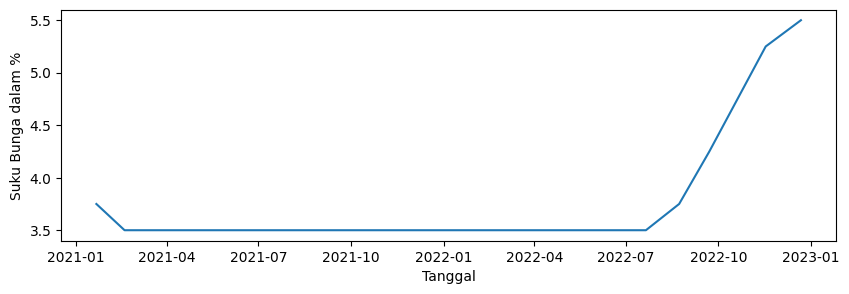

,Tanggal,BI-7Day-RR
0,2021-01-21,3.75
1,2021-02-18,3.50
2,2021-03-18,3.50
3,2021-04-20,3.50
4,2021-05-25,3.50


In [13]:

data_bunga["BI-7Day-RR"] = [float(str(i).replace("%", "")) for i in data_bunga["BI-7Day-RR"]]
x = np.array(data_bunga['Tanggal'])
y = np.array(data_bunga['BI-7Day-RR'])
plt.figure(figsize=(10,3))
plt.xlabel("Tanggal")
plt.ylabel("Suku Bunga dalam %")
plt.plot(x, y)
plt.show()
data_bunga.head()

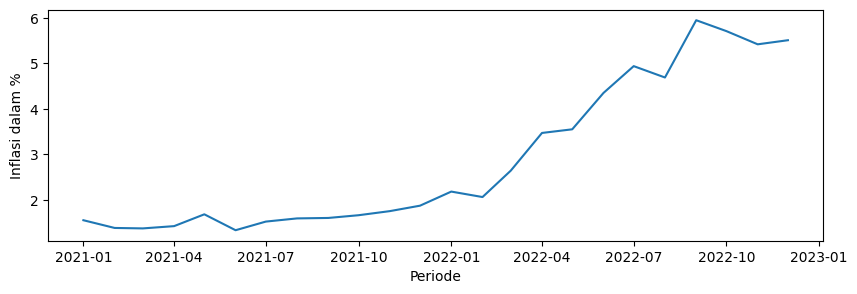

,Periode,Data Inflasi
0,2021-01-01,1.55
1,2021-02-01,1.38
2,2021-03-01,1.37
3,2021-04-01,1.42
4,2021-05-01,1.68


In [11]:

data_inflasi["Data Inflasi"] = [float(str(i).replace("%", "")) for i in data_inflasi["Data Inflasi"]]
x = np.array(data_inflasi['Periode'])
y = np.array(data_inflasi['Data Inflasi'])
plt.figure(figsize=(10,3))
plt.xlabel("Periode")
plt.ylabel("Inflasi dalam %")
plt.plot(x, y)
plt.show()
data_inflasi.head()

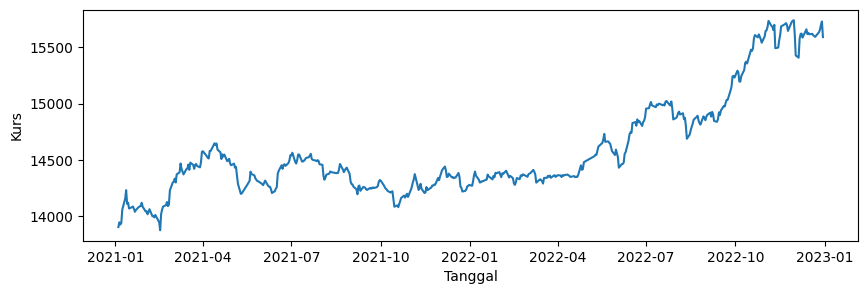

,Tanggal,Kurs
0,2021-01-04,13903
1,2021-01-05,13945
2,2021-01-06,13926
3,2021-01-07,13938
4,2021-01-08,14058


In [18]:
x = np.array(data_kurs['Tanggal'])
y = np.array(data_kurs['Kurs'])
plt.figure(figsize=(10,3))
plt.xlabel("Tanggal")
plt.ylabel("Kurs")
plt.plot(x, y)
plt.show()
data_kurs.head()

In [3]:
data_inflasi['Hari'] = data_inflasi['Periode'].map(lambda x: 
                             pd.date_range(
                                 start=pd.to_datetime(x), 
                                 end=(pd.to_datetime(x) + pd.offsets.MonthEnd()),
                                 freq='D'))
data_inflasi = data_inflasi.explode('Hari')

data_inflasi.tail()

,Periode,Data Inflasi,Hari
23,2022-12-01,5.51 %,2022-12-27
23,2022-12-01,5.51 %,2022-12-28
23,2022-12-01,5.51 %,2022-12-29
23,2022-12-01,5.51 %,2022-12-30
23,2022-12-01,5.51 %,2022-12-31


In [4]:
data_bunga['Hari'] = data_bunga['Tanggal'].map(lambda x: 
                             pd.date_range(
                                 start=pd.offsets.MonthBegin().rollback(x), 
                                 end=(pd.offsets.MonthBegin().rollback(x) + pd.offsets.MonthEnd()),
                                 freq='D'))
data_bunga = data_bunga.explode('Hari')

data_bunga.head()

,Tanggal,BI-7Day-RR,Hari
0,2021-01-21,3.75 %,2021-01-01
0,2021-01-21,3.75 %,2021-01-02
0,2021-01-21,3.75 %,2021-01-03
0,2021-01-21,3.75 %,2021-01-04
0,2021-01-21,3.75 %,2021-01-05


In [5]:
data = data_emas.set_index('tanggal').join(data_kurs.set_index('Tanggal').join(data_inflasi.set_index('Hari').join(data_bunga.set_index('Hari'))))
data.head()

,harga,Kurs,Periode,Data Inflasi,Tanggal,BI-7Day-RR
tanggal,,,,,,
2021-01-02,969000,NaN,NaT,NaN,NaT,NaN
2021-01-04,975000,13903.0,2021-01-01,1.55 %,2021-01-21,3.75 %
2021-01-05,975000,13945.0,2021-01-01,1.55 %,2021-01-21,3.75 %
2021-01-06,981000,13926.0,2021-01-01,1.55 %,2021-01-21,3.75 %
2021-01-07,971000,13938.0,2021-01-01,1.55 %,2021-01-21,3.75 %


In [6]:
data1 = data.drop(columns=['Periode', 'Tanggal'])
data1.head()

,harga,Kurs,Data Inflasi,BI-7Day-RR
tanggal,,,,
2021-01-02,969000,NaN,NaN,NaN
2021-01-04,975000,13903.0,1.55 %,3.75 %
2021-01-05,975000,13945.0,1.55 %,3.75 %
2021-01-06,981000,13926.0,1.55 %,3.75 %
2021-01-07,971000,13938.0,1.55 %,3.75 %


In [7]:
data1["Data Inflasi"] = [float(str(i).replace("%", "")) for i in data1["Data Inflasi"]]
data1["BI-7Day-RR"] = [float(str(i).replace("%", "")) for i in data1["BI-7Day-RR"]]
data1.head()

,harga,Kurs,Data Inflasi,BI-7Day-RR
tanggal,,,,
2021-01-02,969000,NaN,NaN,NaN
2021-01-04,975000,13903.0,1.55,3.75
2021-01-05,975000,13945.0,1.55,3.75
2021-01-06,981000,13926.0,1.55,3.75
2021-01-07,971000,13938.0,1.55,3.75


In [8]:
data1.isnull().sum()

harga             0
Kurs            195
Data Inflasi    195
BI-7Day-RR      195
dtype: int64

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

In [10]:
data2 = data1.dropna()
data2.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 494 entries, 2021-01-04 to 2022-12-30
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   harga         494 non-null    int64  
 1   Kurs          494 non-null    float64
 2   Data Inflasi  494 non-null    float64
 3   BI-7Day-RR    494 non-null    float64
dtypes: float64(3), int64(1)
memory usage: 19.3 KB


In [11]:
data2.isnull().sum()
data2.corr()

,harga,Kurs,Data Inflasi,BI-7Day-RR
harga,1.000000,0.380775,0.536337,0.328066
Kurs,0.380775,1.000000,0.865007,0.864988
Data Inflasi,0.536337,0.865007,1.000000,0.713842
BI-7Day-RR,0.328066,0.864988,0.713842,1.000000


In [12]:
X = data2.iloc[:, 1:4]
y = data2.iloc[:, 0]

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

In [14]:
lr = LinearRegression()
reg = lr.fit(X_train,y_train)



y_pred = reg.predict(X_test)

In [15]:
print(reg)

LinearRegression()


In [15]:
#Calculating MSE
mse = mean_squared_error(y_test, y_pred)
print('MSE:', mse)
#Calculating MAE
mape = mean_absolute_percentage_error(y_test, y_pred)
print('MAPE:', mape)
#Calculating RMSE
#rmse = np.sqrt(mse)
#print('Root Mean Squared Error of testing set:', rmse)

MSE: 591660409.0548072
MAPE: 0.020201952189213123


In [16]:
beta = lr.coef_
alpa = lr.intercept_
print("intersep = ", alpa)
print("koefisien = ", beta)
print("Persamaan regresi linier: y = %.3f" %(alpa), "+ %.3f*x1" %(beta[0]), "+ %.3f*x2" %(beta[1]), "+ %.3f*x3" %(beta[2]))

intersep =  1265596.0715005493
koefisien =  [  -24.52512155 13870.8306758   1285.90623859]
Persamaan regresi linier: y = 1265596.072 + -24.525*x1 + 13870.831*x2 + 1285.906*x3


In [20]:
tabel = pd.DataFrame({'Actual value': y_test, 'Predicted value': y_pred})
tabel

,Actual value,Predicted value
tanggal,,
2022-05-25,992000,960167.787192
2021-05-27,962000,942396.199304
2022-04-27,981000,964625.323329
2021-12-29,932000,946184.337845
2021-04-23,935000,933001.854643
...,...,...
2022-07-06,977000,970373.946860
2021-03-25,924000,934368.423319
2022-02-07,937000,945410.803778


In [21]:
tabel1 = tabel.sort_values('tanggal',ascending=True)
print(tabel1)

            Actual value  Predicted value
tanggal                                  
2021-01-05        975000    949915.187483
2021-01-18        944000    946604.296074
2021-01-20        954000    946972.172897
2021-01-25        958000    946555.245831
2021-02-02        954000    944807.682675
...                  ...              ...
2022-12-21       1016000    966480.411596
2022-12-22       1014000    966652.087447
2022-12-26       1006000    965622.032342
2022-12-27       1008000    965057.954546
2022-12-30       1020000    966701.137690

[99 rows x 2 columns]


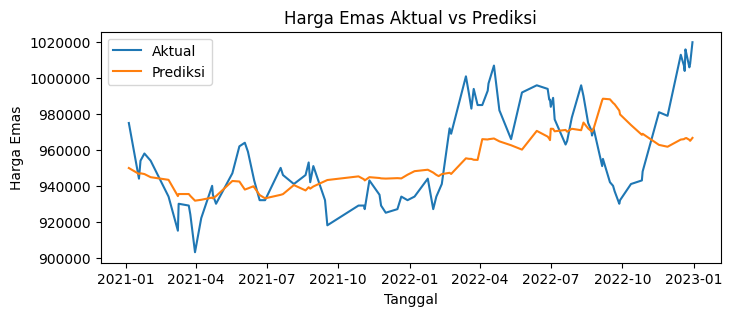

In [22]:
plt.figure(figsize=(8,3))
plt.ticklabel_format(style='plain')
plt.plot(tabel1.index, tabel1['Actual value'], label='Aktual')
plt.plot(tabel1.index, tabel1['Predicted value'], label='Prediksi')
plt.xlabel('Tanggal')
plt.ylabel('Harga Emas')
plt.title('Harga Emas Aktual vs Prediksi')
#plt.ticklabel_format(style='plain')
plt.legend()
plt.show()

In [23]:
import statsmodels.api as sm
X = sm.add_constant(X)
model = sm.OLS(y, X).fit()
predictions = model.predict(X) 
 
print_model = model.summary()
print(print_model)

                            OLS Regression Results                            
Dep. Variable:                  harga   R-squared:                       0.318
Model:                            OLS   Adj. R-squared:                  0.314
Method:                 Least Squares   F-statistic:                     76.18
Date:                Tue, 12 Dec 2023   Prob (F-statistic):           1.85e-40
Time:                        15:04:06   Log-Likelihood:                -5632.6
No. Observations:                 494   AIC:                         1.127e+04
Df Residuals:                     490   BIC:                         1.129e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         1.262e+06   7.64e+04     16.512   

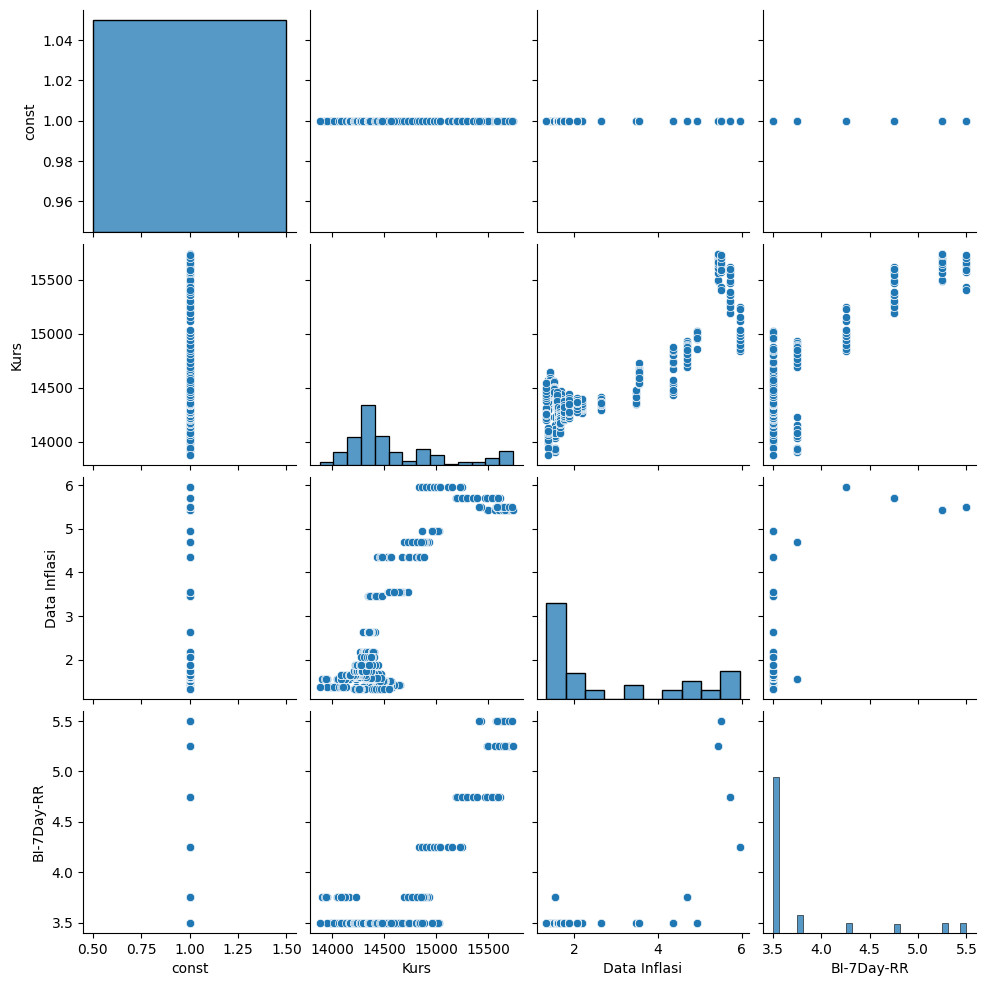

In [21]:
import seaborn as sns
sns.pairplot(X)